In [312]:
# Import packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [313]:
# read csv file
df_raw = pd.read_csv('ims_setup_project02.csv')

In [314]:
# First exploration of the data
print("Five first rows:")
display(df_raw.head(5))
print("Data frame size:")
display(df_raw.shape)
print("Column names:")
display(df_raw.columns)
print("Basic statistics:")
display(df_raw.describe())
print("Missing values:")
display(df_raw.isna().sum())

Five first rows:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
0,1,5,35,33.0949,286.761
1,2,5,35,32.9325,287.079
2,3,5,35,33.0858,287.261
3,4,5,35,33.0472,287.059
4,5,5,35,33.0534,287.463


Data frame size:


(135, 5)

Column names:


Index(['lap', 'rear_wing_angle_deg', 'rear_ride_height_mm', 'sector_3_time_s',
       'top_speed_kph'],
      dtype='str')

Basic statistics:


,lap,rear_wing_angle_deg,rear_ride_height_mm,sector_3_time_s,top_speed_kph
count,135.000000,135.000000,135.000000,135.000000,135.000000
mean,3.000000,9.000000,40.000000,31.803734,284.178563
std,1.419481,2.591605,4.097688,0.542766,1.778668
min,1.000000,5.000000,35.000000,31.061300,280.887000
25%,2.000000,7.000000,35.000000,31.413650,282.690500
50%,3.000000,9.000000,40.000000,31.599500,284.373000
75%,4.000000,11.000000,45.000000,32.041350,285.638000
max,5.000000,13.000000,45.000000,33.094900,287.463000


Missing values:


lap                    0
rear_wing_angle_deg    0
rear_ride_height_mm    0
sector_3_time_s        0
top_speed_kph          0
dtype: int64

In [315]:
# Make a copy and convert columns to numeric
df = df_raw[["lap","rear_wing_angle_deg","rear_ride_height_mm","sector_3_time_s","top_speed_kph"]].copy()
for columns in df.columns:
    df[columns] = pd.to_numeric(df[columns], errors='coerce')

In [316]:
# Grouped data frame
df_grouped = df.groupby(["rear_wing_angle_deg","rear_ride_height_mm"], as_index=False).agg(
    mean_sector_3_time_s = ("sector_3_time_s","mean"), std_sector_3_time_s = ("sector_3_time_s","std"),
    mean_top_speed_kph = ("top_speed_kph","mean"), std_top_speed_kph = ("top_speed_kph","std"), valid_laps = ("lap","count")
    )

In [317]:
# Display grouped data frame and number of setups
display(df_grouped)
print("Number of unique setups:", df_grouped.shape[0])
df_grouped.to_csv("mgfreita_pr02_grouped.csv", index=False)

,rear_wing_angle_deg,rear_ride_height_mm,mean_sector_3_time_s,std_sector_3_time_s,mean_top_speed_kph,std_top_speed_kph,valid_laps
0,5,35,33.04276,0.064925,287.1246,0.260628,5
1,5,40,32.85104,0.104126,286.7078,0.260848,5
2,5,45,32.99286,0.022043,286.6164,0.061272,5
3,6,35,32.51308,0.053101,286.5346,0.172712,5
4,6,40,32.38096,0.050323,286.2574,0.229553,5
5,6,45,32.44690,0.077138,285.7634,0.171296,5
6,7,35,32.03248,0.035651,285.8530,0.289042,5
7,7,40,31.86244,0.059775,285.3564,0.242663,5
8,7,45,32.01484,0.053106,285.0412,0.182341,5
9,8,35,31.68490,0.054910,285.3770,0.150690,5


Number of unique setups: 27


In [318]:
# Splitting the data into training and testing (seed = 42)
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df_grouped, test_size=0.25, random_state=42)
print("Number of training data points:",df_train.shape[0])
print("Number of testing data points:", df_test.shape[0])

Number of training data points: 20
Number of testing data points: 7


The split of training and test data occur only after grouping to avoid data leakage. If the splitting happens before, it may happen that the same setup configuration can be used both for training and evaluation, leading to potential overfitting issues.  

In [319]:
# Design matrix function
def design_matrix(x1,x2):
    x1 = x1.to_numpy()
    x2 = x2.to_numpy()
    X = np.column_stack([np.ones(x1.shape), x1, x2, x1**2, x2**2, x1*x2])
    return X

In [320]:
# Design variables & design matrix
x1_train = df_train["rear_wing_angle_deg"]
x2_train = df_train["rear_ride_height_mm"]
XDM_train = design_matrix(x1_train, x2_train)

In [321]:
# Regression coefficients for mean lap time response variable
y1_train = df_train["mean_sector_3_time_s"].to_numpy()
b_time_train = np.linalg.pinv(XDM_train)@y1_train

In [322]:
# Regression coefficients for top speed response variable
y2_train = df_train["mean_top_speed_kph"].to_numpy()
b_speed_train = np.linalg.pinv(XDM_train)@y2_train

In [323]:
# Display regression coefficients
print("b_time_train =", b_time_train)
print("b_speed_train =", b_speed_train)

b_time_train = [ 4.73886880e+01 -1.29838222e+00 -4.80678309e-01  5.43427458e-02
  5.67136642e-03  3.88185285e-03]
b_speed_train = [ 2.95038265e+02 -5.55986025e-01 -2.02484393e-01 -7.21976597e-03
  1.70273178e-03  3.35132466e-04]


In [324]:
# Predicting mean lap time and top speed for the test set
x1_test = df_test["rear_wing_angle_deg"]
x2_test = df_test["rear_ride_height_mm"]
XDM_test = design_matrix(x1_test, x2_test)
y1_pred = XDM_test @ b_time_train
y2_pred = XDM_test @ b_speed_train

In [325]:
# Test results for mean lap time
y1_test = df_test["mean_sector_3_time_s"].to_numpy()
time_residuals = y1_pred-y1_test
time_mse = np.sqrt(np.mean(time_residuals**2))
time_SSres = np.sum(time_residuals**2)
time_SStot = np.sum((y1_test-np.mean(y1_test))**2)
time_r2 = 1-time_SSres/time_SStot

In [326]:
# Test results for top speed
y2_test = df_test["mean_top_speed_kph"].to_numpy()
speed_residuals = y2_pred-y2_test
speed_mse = np.sqrt(np.mean(speed_residuals**2))
SSres_speed = np.sum(speed_residuals**2)  
SStot_speed = np.sum((y2_test-np.mean(y2_test))**2)
speed_r2 = 1-SSres_speed/SStot_speed

In [327]:
# Test results dataframe
df_validation = pd.DataFrame({ "time_mse":   [time_mse], "time_r2": [time_r2],
                             "speed_mse": [speed_mse], "speed_r2": [speed_r2]})
display(df_validation)
df_validation.to_csv("mgfreita_pr02_validation.csv", index=False)

,time_mse,time_r2,speed_mse,speed_r2
0,0.02585,0.997994,0.164353,0.985828


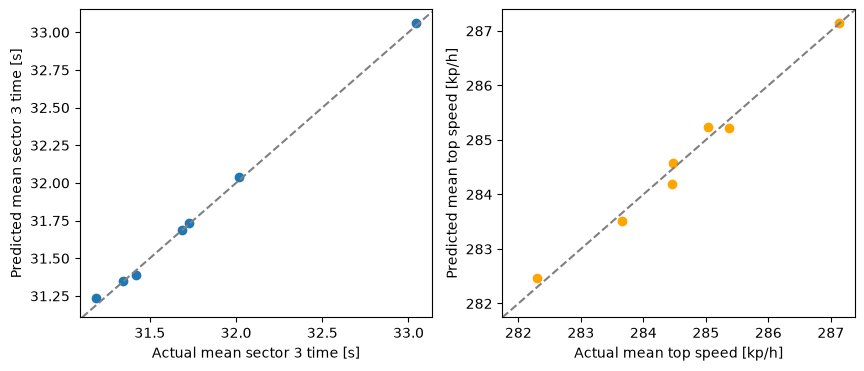

In [328]:
# Plot of actual vs predicted values for mean lap time and top speed
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y1_test, y1_pred)
axes[0].set_xlabel("Actual mean sector 3 time [s]")
axes[0].set_ylabel("Predicted mean sector 3 time [s]")
axes[0].axline((31.2, 31.2), slope=1, linestyle="--", color="grey")
axes[1].scatter(y2_test, y2_pred, color="orange")
axes[1].set_xlabel("Actual mean top speed [kp/h]")
axes[1].set_ylabel("Predicted mean top speed [kp/h]")
axes[1].axline((282, 282), slope=1, linestyle="--", color="grey")
plt.savefig("mgfreita_pr02_validation.png")
plt.show()

In both plots above, we see that points don't fall away from the y=x line, especially considering the scale of values within each response variable. That observation is aligned with the fact that the RMSE for sector 3 lap times and top speed are relatively small. The RMSE error is sensitive to the scale of values, so this might explain why the actual vs predicted points for top speed tend to agree less than the points for the sector 3 time.

In [329]:
# Coefficients using all data
x1 = df_grouped["rear_wing_angle_deg"]
x2 = df_grouped["rear_ride_height_mm"]
XDM = design_matrix(x1,x2)
y1 = df_grouped["mean_sector_3_time_s"].to_numpy()
y2 = df_grouped["mean_top_speed_kph"].to_numpy()
b_time = np.linalg.pinv(XDM)@y1
b_speed = np.linalg.pinv(XDM)@y2

In [330]:
# Predicted response variables functions
def predict_sector_time(x):
    return b_time[0] + b_time[1]*x[0] + b_time[2]*x[1] + b_time[3]*x[0]**2 + b_time[4]*x[1]**2 + b_time[5]*x[0]*x[1]
def predict_top_speed(x):
    return b_speed[0] + b_speed[1]*x[0] + b_speed[2]*x[1] + b_speed[3]*x[0]**2 + b_speed[4]*x[1]**2 + b_speed[5]*x[0]*x[1]
# Test the prediction functions with a sample input
predicted_time = predict_sector_time([9, 40])
predicted_speed = predict_top_speed([9, 40])
print("Predicted mean sector 3 time for rear wing angle = 9 deg and rear ride height = 40 mm:", predicted_time)
print("Predicted mean top speed for rear wing angle = 9 deg and rear ride height = 40 mm:", predicted_speed)

Predicted mean sector 3 time for rear wing angle = 9 deg and rear ride height = 40 mm: 31.340928032708646
Predicted mean top speed for rear wing angle = 9 deg and rear ride height = 40 mm: 284.2602979316982


In [331]:
# Testing bounds
wing_bounds = (df_grouped["rear_wing_angle_deg"].min(), df_grouped["rear_wing_angle_deg"].max())
ride_height_bounds = (df_grouped["rear_ride_height_mm"].min(), df_grouped["rear_ride_height_mm"].max())

In [332]:
# Evaluate the predicted response variables at the grid points
x1_plt = np.linspace(wing_bounds[0], wing_bounds[1], 101)
x2_plt = np.linspace(ride_height_bounds[0], ride_height_bounds[1], 101)
x1_grid, x2_grid = np.meshgrid(x1_plt, x2_plt)
y1_grid = predict_sector_time([x1_grid.ravel(), x2_grid.ravel()])

In [333]:
wing_bounds

(np.int64(5), np.int64(13))

In [334]:
# Locate the minimum predicted mean sector 3 time 
y1_min_index = np.argmin(y1_grid)
x1_opt = x1_grid.ravel()[y1_min_index]
x2_opt = x2_grid.ravel()[y1_min_index]
y1_opt = predict_sector_time([x1_opt, x2_opt])
y2_opt = predict_top_speed([x1_opt, x2_opt])
print("Optimal rear wing angle [deg]:", x1_opt)
print("Optimal rear ride height [mm]:", x2_opt)
print("Optimal mean sector 3 time [s]:", y1_opt)
print("Top speed [km/h] of the optimal configuration:", y2_opt)

Optimal rear wing angle [deg]: 10.52
Optimal rear ride height [mm]: 38.9
Optimal mean sector 3 time [s]: 31.210586204804475
Top speed [km/h] of the optimal configuration: 283.2834515711555


In [335]:
# Optimal configuration using scipy.optimize
import scipy.optimize as opt
objective = lambda x: predict_sector_time(x)
x0 = [(wing_bounds[1]+wing_bounds[0])/2, (ride_height_bounds[1]+ride_height_bounds[0])/2]  
result_unconstrained = opt.minimize(objective, x0, bounds=[wing_bounds, ride_height_bounds], method = "L-BFGS-B")

In [336]:
print("Sucess = ", result_unconstrained.success)
print("Message = ", result_unconstrained.message)
print("Optimal rear wing angle [deg]:", result_unconstrained.x[0])
print("Optimal rear ride height [mm]:", result_unconstrained.x[1])
print("Optimal mean sector 3 time [s]:", result_unconstrained.fun)
print("Top speed [km/h] of the optimal configuration:", predict_top_speed(result_unconstrained.x))

Sucess =  True
Message =  CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Optimal rear wing angle [deg]: 10.537272410517105
Optimal rear ride height [mm]: 38.87386184846888
Optimal mean sector 3 time [s]: 31.210567531670257
Top speed [km/h] of the optimal configuration: 283.2728636531646


In [337]:
# Grid resolution vs optimizer
x1_resolution = (wing_bounds[1]-wing_bounds[0])/101
x2_resolution = (ride_height_bounds[1]-ride_height_bounds[0])/101
deltax1_opt = result_unconstrained.x[0]-x1_opt
deltax2_opt = result_unconstrained.x[1]-x2_opt
print("Is the deltax1_opt less than the grid resolution?", deltax1_opt<x1_resolution)
print("Is the deltax2_opt less than the grid resolution?", deltax2_opt<x2_resolution)

Is the deltax1_opt less than the grid resolution? True
Is the deltax2_opt less than the grid resolution? True


The grid method and the sicipy optimizer search of the optimal configuration does agree up to the resolution of the grid.

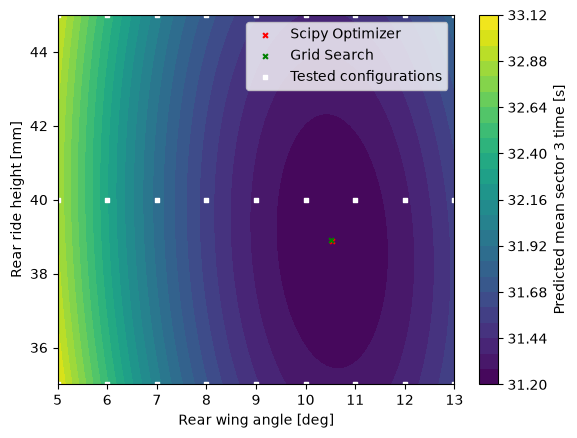

In [338]:
# Contour plot of optimal configurations and tested configurations
plt.contourf(x1_plt, x2_plt, y1_grid.reshape(x1_grid.shape), levels = 25)
plt.colorbar(label="Predicted mean sector 3 time [s]")
plt.scatter(result_unconstrained.x[0], result_unconstrained.x[1], marker = 'x', color="red", s = 12, label="Scipy Optimizer")
plt.scatter(x1_opt, x2_opt, marker = 'x', color="green", s = 12,  label="Grid Search")
plt.scatter(x1,x2, color="white", s = 10, label="Tested configurations", marker = 's')
plt.xlabel("Rear wing angle [deg]")
plt.ylabel("Rear ride height [mm]")
plt.legend()
plt.savefig("mgfreita_pr02_unconstrained.png")

In [339]:
# Top speed constraint
V_min = 284
def top_speed_constraint(x):
    return predict_top_speed(x) - V_min

In [340]:
# Constrained optimization
non_linear_constraint = opt.NonlinearConstraint(lambda x: top_speed_constraint(x), 0, np.inf)
result_constrained = opt.minimize(objective, x0, bounds=[wing_bounds, ride_height_bounds], 
                                  constraints= non_linear_constraint, method = "SLSQP")

In [341]:
# Constrained optimization results
print("Sucess = ", result_constrained.success)
print("Message = ", result_constrained.message)
print("Optimal rear wing angle [deg]:", result_constrained.x[0])
print("Optimal rear ride height [mm]:", result_constrained.x[1])
print("Optimal mean sector 3 time [s]:", result_constrained.fun)
print("Top speed [km/h] of the optimal configuration:", predict_top_speed(result_constrained.x))
print("Top speed margin [km/h]:", predict_top_speed(result_constrained.x) - V_min)

Sucess =  True
Message =  Optimization terminated successfully
Optimal rear wing angle [deg]: 9.541826588737443
Optimal rear ride height [mm]: 38.327667443558305
Optimal mean sector 3 time [s]: 31.26854806616058
Top speed [km/h] of the optimal configuration: 283.999999988011
Top speed margin [km/h]: -1.1989016002189601e-08


Up to the error margin of 0.05 km/h, the constraint is active for the reported top speed of 283.9999999154321 km/h.

In [342]:
# Optimization for different initial guesses
x0_a = [12 , 43]
x0_b = [6,37]
x0_c = [10,40]
result_constrained_a = opt.minimize(objective, x0_a, bounds=[wing_bounds, ride_height_bounds], 
                                  constraints= non_linear_constraint, method = "SLSQP")
result_constrained_b = opt.minimize(objective, x0_b, bounds=[wing_bounds, ride_height_bounds],
                                  constraints= non_linear_constraint, method = "SLSQP")
result_constrained_c = opt.minimize(objective, x0_c, bounds=[wing_bounds, ride_height_bounds],
                                  constraints= non_linear_constraint, method = "SLSQP")

In [343]:
# Create dataframe to store optimization results for different initial guesses
df_optimization_runs = pd.DataFrame({"initial_x1": [x0_a[0], x0_b[0], x0_c[0]], "initial_x2": [x0_a[1], x0_b[1], x0_c[1]],
                                     "optimal_x1": [result_constrained_a.x[0], result_constrained_b.x[0], result_constrained_c.x[0]],
                                     "optimal_x2": [result_constrained_a.x[1], result_constrained_b.x[1], result_constrained_c.x[1]],
                                     "sector_time_s": [result_constrained_a.fun, result_constrained_b.fun, result_constrained_c.fun],
                                     "top_speed_kph": [predict_top_speed(result_constrained_a.x), predict_top_speed(result_constrained_b.x), predict_top_speed(result_constrained_c.x)],
                                     "top_speed_margin_kph": [top_speed_constraint(result_constrained_a.x), top_speed_constraint(result_constrained_b.x), top_speed_constraint(result_constrained_c.x)],
                                     "sucess": [result_constrained_a.success, result_constrained_b.success, result_constrained_c.success]})

In [344]:
# Display optimization results and save to CSV 
display(df_optimization_runs)
df_optimization_runs.to_csv("mgfreita_pr02_optimization_runs.csv", index=False)

,initial_x1,initial_x2,optimal_x1,optimal_x2,sector_time_s,top_speed_kph,top_speed_margin_kph,sucess
0,12,43,9.541821,38.327725,31.268548,284.0,-6.679670e-08,True
1,6,37,9.541829,38.327643,31.268548,284.0,-1.344858e-09,True
2,10,40,9.541819,38.327750,31.268548,284.0,-2.775437e-09,True


Up to grid resolution, all three different candidates converge to the same optimal configuration. Up to the margin of 0.05 km/h, all three candidate satsifies the requirement of at least 284 km/h.

In [345]:
# Evaluate the predicted top speed at the grid points
y2_grid = predict_top_speed([x1_grid.ravel(), x2_grid.ravel()])
y2_feasible = y2_grid >= V_min

In [353]:
# Calculate sector 3 lap time for feasible configurations
y1_feasible = y1_grid[y2_feasible]
index_feasible = np.argmin(y2_feasible)
y1_opt_feasible = np.min(y1_feasible)
y2_opt_feasible = predict_top_speed([x1_grid.ravel()[index_feasible], x2_grid.ravel()[index_feasible]])
print("The optimal lap time of feasible configurations is:",  np.min(y1_feasible))
print("The optimal configuration of feasible configurations is: rear wing angle deg = ", x1_grid.ravel()[index_feasible], "rear ride height mm = ", x2_grid.ravel()[index_feasible])
print("The predicted top speed in km/h is:", y2_opt_feasible)

The optimal lap time of feasible configurations is: 31.269140200450057
The optimal configuration of feasible configurations is: rear wing angle deg =  9.879999999999999 rear ride height mm =  35.0
The predicted top speed in km/h is: 283.9632022643965


The optimal configuration obtained from grid searching among feasible configurations substantially agrees with the SLSQP solution only  with respect to the wing angle, predicted sector 3 time and predicted top speed. Interestingly enough, the optimal rear ride heights are substantially different with a difference of about 3.3 mm.

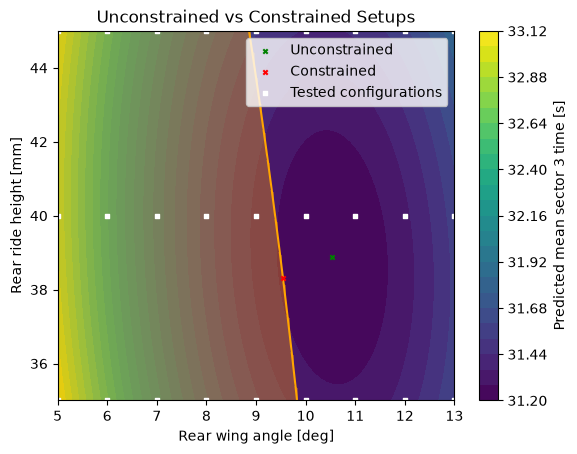

In [349]:
plt.contourf(x1_plt, x2_plt, y1_grid.reshape(x1_grid.shape), levels = 25)
plt.colorbar(label="Predicted mean sector 3 time [s]")
plt.scatter(result_unconstrained.x[0], result_unconstrained.x[1],marker = 'x',color="green", s = 10, label="Unconstrained")
plt.contour(x1_plt, x2_plt, y2_grid.reshape(x1_grid.shape), levels=[284], colors = 'orange', zorder=1)
plt.contourf(x1_plt, x2_plt, y2_grid.reshape(x1_grid.shape) >= 284, levels=[0.5, 1], colors="orange",alpha=0.35)
plt.scatter(result_constrained.x[0], result_constrained.x[1], marker = 'x', color="red", s = 10, label = "Constrained")
plt.scatter(x1,x2, color="white", marker = 's', s = 10, label="Tested configurations")
plt.xlabel("Rear wing angle [deg]")
plt.ylabel("Rear ride height [mm]")
plt.legend()
plt.title("Unconstrained vs Constrained Setups")
plt.savefig("mgfreita_pr02_constrained.png")
plt.show()


In [364]:
# Sector 3 lap time and top speed difference constrained vs unconstrained
print("Delta sector 3 time:", np.abs(predict_sector_time(result_constrained.x) - predict_sector_time(result_unconstrained.x)))
print("Delta top speed:", np.abs(predict_top_speed(result_constrained.x) - predict_top_speed(result_unconstrained.x)))

Delta sector 3 time: 0.05798053449032281
Delta top speed: 0.7271363348463638


The optimal setup satisfying the top speed requirement produces a lap time which is not substantially worse than the optimal unconstrained configuration (difference of about 0.06s), while producing a difference of top speed higher than the threshold of 0.05km/h (difference of about 0.7 km/h).   

The optimal setup satisfying the top speed requirement is more defensible, since exchaning sector 3 lap time for extra top speed may help reduce the overall lap time. 